In [ ]:
import math, os, time, numpy as np, torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
def generate_data(data: str, batch_size: int = 200, device: str = "cpu") -> torch.Tensor:
    """
    Generate synthetic 2D datasets without rewards.

    Parameters
    ----------
    data : {"rings", "8gaussians", "2spirals", "checkerboard"}
    batch_size : int
    device : str

    Returns
    -------
    X : torch.FloatTensor of shape (batch_size, 2)
    """
    def torch_linspace_exclusive(start, stop, steps, device="cpu"):
        return torch.linspace(start, stop, steps + 1, device=device)[:-1]

    if data == "rings":
        # split into 4 rings
        n4 = n3 = n2 = batch_size // 4
        n1 = batch_size - n4 - n3 - n2

        angle4 = torch_linspace_exclusive(0, 2 * np.pi, n4, device=device)
        angle3 = torch_linspace_exclusive(0, 2 * np.pi, n3, device=device)
        angle2 = torch_linspace_exclusive(0, 2 * np.pi, n2, device=device)
        angle1 = torch_linspace_exclusive(0, 2 * np.pi, n1, device=device)

        circ4 = torch.stack([torch.cos(angle4), torch.sin(angle4)], dim=1)         # r = 1.00
        circ3 = torch.stack([torch.cos(angle3), torch.sin(angle3)], dim=1) * 0.75  # r = 0.75
        circ2 = torch.stack([torch.cos(angle2), torch.sin(angle2)], dim=1) * 0.50  # r = 0.50
        circ1 = torch.stack([torch.cos(angle1), torch.sin(angle1)], dim=1) * 0.25  # r = 0.25

        X = torch.cat([circ4, circ3, circ2, circ1], dim=0) * 3.0
        X = X + torch.randn_like(X) * 0.08  # small Gaussian noise

        perm = torch.randperm(X.size(0), device=device)
        return X[perm].float()

    elif data == "8gaussians":
        scale = 4.0
        centers = torch.tensor([
            [0, 1],
            [-1/np.sqrt(2),  1/np.sqrt(2)],
            [-1, 0],
            [-1/np.sqrt(2), -1/np.sqrt(2)],
            [0, -1],
            [ 1/np.sqrt(2), -1/np.sqrt(2)],
            [1, 0],
            [ 1/np.sqrt(2),  1/np.sqrt(2)]
        ], dtype=torch.float32, device=device) * scale

        idx = torch.randint(0, 8, (batch_size,), device=device)
        X = torch.randn(batch_size, 2, device=device) * 0.5
        X = (X + centers[idx]) / 1.414

        perm = torch.randperm(X.size(0), device=device)
        return X[perm].float()

    elif data == "2spirals":
        half = batch_size // 2
        n = torch.sqrt(torch.rand(half, 1, device=device)) * (3 * np.pi)

        d1x = -torch.cos(n) * n + torch.rand(half, 1, device=device) * 0.5
        d1y =  torch.sin(n) * n + torch.rand(half, 1, device=device) * 0.5
        spiral1 = torch.cat([d1x, d1y], dim=1)

        spiral2 = -spiral1
        X = torch.cat([spiral1, spiral2], dim=0) / 3.0
        X = X + torch.randn_like(X) * 0.1

        perm = torch.randperm(X.size(0), device=device)
        # if batch_size is odd, drop the last extra sample after permuting
        return X[perm][:batch_size].float()

    elif data == "checkerboard":
        # x1 ~ Uniform([-2, 2])
        x1 = torch.rand(batch_size, device=device) * 4 - 2
        # x2 with alternating offset by parity of floor(x1)
        x2_offset = torch.rand(batch_size, device=device) - (
            torch.randint(0, 2, (batch_size,), device=device, dtype=torch.float32) * 2
        )
        x2 = x2_offset + (torch.floor(x1) % 2)

        X = torch.stack([x1, x2], dim=1) * 2

        perm = torch.randperm(X.size(0), device=device)
        return X[perm].float()

    else:
        raise ValueError(f"Unknown dataset type: {data}")

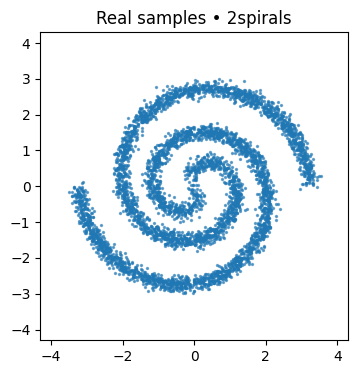

In [ ]:
# --- Choose dataset & dataloader ---
data_type = "2spirals"   # "rings" | "8gaussians" | "2spirals" | "checkerboard"
batch_size = 1024
dataset_size = 50000

X_real = generate_data(data_type, batch_size=dataset_size, device="cpu")
ds = TensorDataset(X_real)  # (N,2)
dl = DataLoader(ds, batch_size=batch_size, shuffle=True, drop_last=True,
                num_workers=0, pin_memory=(device.type=="cuda"))

plt.figure(figsize=(4,4))
sub = X_real[:5000].numpy()
plt.scatter(sub[:,0], sub[:,1], s=2, alpha=0.6)
plt.gca().set_aspect('equal', 'box')
plt.xlim(-4.3,4.3); plt.ylim(-4.3,4.3)
plt.title(f"Real samples • {data_type}")
plt.show()

In [ ]:
class MLPGenerator(nn.Module):
    def __init__(self, z_dim=16, hidden=(256,256,256), out_dim=2):
        super().__init__()
        layers = []
        in_dim = z_dim
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(inplace=True)]
            in_dim = h
        layers += [nn.Linear(in_dim, out_dim)]
        self.net = nn.Sequential(*layers)
    def forward(self, z):
        return self.net(z)

class MLPDiscriminator(nn.Module):
    def __init__(self, in_dim=2, hidden=(256,256,256)):
        super().__init__()
        layers = []
        d = in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.LeakyReLU(0.2, inplace=True)]
            d = h
        layers += [nn.Linear(d, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def weights_init(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, a=0.2, nonlinearity='leaky_relu')
        if m.bias is not None:
            nn.init.zeros_(m.bias)


def sample_noise(n, z_dim, device):
    return torch.randn(n, z_dim, device=device)

In [ ]:
# === Visualization utilities ===
from ipywidgets import IntSlider, Play, jslink, HBox, VBox, HTML, Output
from IPython.display import display
from tqdm import tqdm


def make_grid(xmin=-4.1, xmax=4.1, ymin=-4.1, ymax=4.1, n=140, device="cpu"):
    xs = np.linspace(xmin, xmax, n)
    ys = np.linspace(ymin, ymax, n)
    xx, yy = np.meshgrid(xs, ys)
    grid = np.stack([xx.ravel(), yy.ravel()], axis=1).astype(np.float32)
    grid_t = torch.from_numpy(grid).to(device)
    return xs, ys, grid_t


@torch.no_grad()
def capture_snapshot(G, D, X_real, viz_noise, xs, ys, grid_t, data_type, device, epoch):
    G.eval(); D.eval()
    fake_viz = G(viz_noise).detach().cpu().numpy()
    real_viz = X_real[:len(viz_noise)].detach().cpu().numpy()
    scores   = D(grid_t).view(len(ys), len(xs)).detach().cpu().numpy()
    return {
        "epoch": int(epoch),
        "data_type": data_type,
        "real": real_viz,
        "fake": fake_viz,
        "xs": xs, "ys": ys, "scores": scores,
    }


def init_live_browser():
    import ipywidgets as W
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    out = Output()
    fig, (ax_real, ax_score, ax_fake) = plt.subplots(1, 3, figsize=(15,4))
    fig.subplots_adjust(wspace=0.35)

    cax = inset_axes(ax_score, width="3%", height="90%", loc='right', borderpad=1)

    info   = W.HTML(value="Ready")
    play   = W.Play(interval=400, value=0, min=0, max=0, step=1, description="▶")
    slider = W.IntSlider(value=0, min=0, max=0, step=1,
                         description="epoch idx", continuous_update=True)

    W.link((play, 'value'), (slider, 'value'))

    snapshots = []
    state = {"cbar": None}

    def draw_idx(idx):
        snap = snapshots[idx]
        xs, ys = snap["xs"], snap["ys"]

        ax_real.clear()
        ax_real.set_title(f"Real • {snap['data_type']}")
        ax_real.scatter(snap["real"][:,0], snap["real"][:,1], s=2, alpha=0.6)
        ax_real.set_xlim(-4.1,4.1); ax_real.set_ylim(-4.1,4.1); ax_real.set_aspect('equal','box')

        ax_score.clear()
        ax_score.set_title("Discriminator Score")
        cf = ax_score.contourf(xs, ys, snap["scores"], levels=20, alpha=0.9)
        ax_score.set_xlim(-4.1,4.1); ax_score.set_ylim(-4.1,4.1); ax_score.set_aspect('equal','box')
        if state["cbar"] is None:
            state["cbar"] = fig.colorbar(cf, cax=cax)
        else:
            state["cbar"].update_normal(cf)

        ax_fake.clear()
        ax_fake.set_title(f"Samples @ epoch {snap['epoch']}")
        ax_fake.scatter(snap["fake"][:,0], snap["fake"][:,1], s=2, alpha=0.6)
        ax_fake.set_xlim(-4.1,4.1); ax_fake.set_ylim(-4.1,4.1); ax_fake.set_aspect('equal','box')

        info.value = f"Epoch <b>{snap['epoch']}</b>  |  Snapshots: {len(snapshots)}"
        with out:
            out.clear_output(wait=True)
            display(fig)

    def on_slider(change):
        if change["name"] == "value" and snapshots:
            draw_idx(change["new"])

    slider.observe(on_slider, names="value")

    def push_snapshot(snap):
        snapshots.append(snap)
        new_max = len(snapshots) - 1
        slider.max = new_max
        play.max   = new_max
        play.value = new_max

        if not snapshots:
            with out:
                out.clear_output(wait=True)
                display(fig)

    ui = W.VBox([W.HBox([play, slider, info]), out])
    display(ui)
    return push_snapshot

In [ ]:
import random
import numpy as np
import torch

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### Problem 4.1, Part 1 - Classic GAN experiments

In [ ]:

# Classic GAN: one training implementation for all experiments
# Uses existing generate_data, MLPGenerator, MLPDiscriminator, and weights_init.

from pathlib import Path

RESULT_DIR = Path("classic_gan_results")
RESULT_DIR.mkdir(exist_ok=True)

def train_classic_gan(dataset, experiment, lr=2e-4, n_critic=1,
                      epochs=250, batch_size=1024, dataset_size=50000,
                      hidden=(256, 256, 256), seed=42, optimizer="adam"):

    """Train an independent vanilla GAN and save results."""

    seed_everything(seed)

    # Prepare dataset
    real_cpu = generate_data(
        dataset, batch_size=dataset_size, device="cpu"
    )

    loader = DataLoader(
        TensorDataset(real_cpu),
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    # Initialize models
    z_dim = 16

    gen = MLPGenerator(z_dim=z_dim, hidden=hidden).to(device)
    disc = MLPDiscriminator(hidden=hidden).to(device)

    gen.apply(weights_init)
    disc.apply(weights_init)

    # Choose optimizer
    if optimizer.lower() == "adam":
        opt_g = torch.optim.Adam(
            gen.parameters(), lr=lr, betas=(0.5, 0.999)
        )
        opt_d = torch.optim.Adam(
            disc.parameters(), lr=lr, betas=(0.5, 0.999)
        )

    elif optimizer.lower() == "rmsprop":
        opt_g = torch.optim.RMSprop(gen.parameters(), lr=lr)
        opt_d = torch.optim.RMSprop(disc.parameters(), lr=lr)

    else:
        raise ValueError(f"Unsupported optimizer: {optimizer}")

    criterion = nn.BCEWithLogitsLoss()
    g_losses, d_losses = [], []
    snapshots = {}

    fixed_z = sample_noise(5000, z_dim, device)

    # Training loop
    for epoch in range(1, epochs + 1):
        gen.train()
        disc.train()

        running_g, running_d, count = 0.0, 0.0, 0

        for (real_batch,) in loader:
            real = real_batch.to(device, non_blocking=True)
            B = real.shape[0]

            # Train discriminator
            for _ in range(n_critic):
                z = sample_noise(B, z_dim, device)

                with torch.no_grad():
                    fake_for_d = gen(z)

                real_logits = disc(real)
                fake_logits = disc(fake_for_d)

                d_loss = (
                    criterion(
                        real_logits, torch.ones_like(real_logits)
                    )
                    + criterion(
                        fake_logits, torch.zeros_like(fake_logits)
                    )
                )

                opt_d.zero_grad(set_to_none=True)
                d_loss.backward()
                opt_d.step()

            # Train generator
            z = sample_noise(B, z_dim, device)
            fake = gen(z)
            logits = disc(fake)

            g_loss = criterion(
                logits, torch.ones_like(logits)
            )

            opt_g.zero_grad(set_to_none=True)
            g_loss.backward()
            opt_g.step()

            running_g += g_loss.item()
            running_d += d_loss.item()
            count += 1

        g_losses.append(running_g / count)
        d_losses.append(running_d / count)

        # Save training snapshots
        if epoch in (10, 50, 100, epochs):
            gen.eval()

            with torch.no_grad():
                snapshots[epoch] = gen(fixed_z).cpu().numpy()

            print(
                f"{dataset} / {experiment}: epoch {epoch}/{epochs}, "
                f"G={g_losses[-1]:.3f}, D={d_losses[-1]:.3f}"
            )

    # Plot real vs. generated samples
    snapshots_to_show = sorted(snapshots)

    fig, axes = plt.subplots(
        1,
        1 + len(snapshots_to_show),
        figsize=(4 * (1 + len(snapshots_to_show)), 4)
    )

    ref = real_cpu[:5000].numpy()

    axes[0].scatter(
        ref[:, 0], ref[:, 1], s=2, alpha=0.5
    )
    axes[0].set_title("Real samples")

    for ax, epoch in zip(axes[1:], snapshots_to_show):
        arr = snapshots[epoch]

        ax.scatter(
            arr[:, 0], arr[:, 1], s=2, alpha=0.5
        )
        ax.set_title(f"Generated — epoch {epoch}")

    for ax in axes:
        ax.set_xlim(-4.3, 4.3)
        ax.set_ylim(-4.3, 4.3)
        ax.set_aspect("equal", "box")

    fig.suptitle(
        f"{dataset}: {experiment} | "
        f"lr={lr}, n_critic={n_critic}, optimizer={optimizer}"
    )

    fig.tight_layout()

    fig.savefig(
        RESULT_DIR / f"{dataset}_{experiment}_samples.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    # Plot losses
    fig, ax = plt.subplots(figsize=(7, 3.5))

    ax.plot(
        range(1, epochs + 1),
        d_losses,
        label="Discriminator"
    )

    ax.plot(
        range(1, epochs + 1),
        g_losses,
        label="Generator"
    )

    ax.set(
        xlabel="Epoch",
        ylabel="Mean batch loss",
        title=f"{dataset}: {experiment} — Classic GAN losses"
    )

    ax.legend()
    fig.tight_layout()

    fig.savefig(
        RESULT_DIR / f"{dataset}_{experiment}_losses.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    return {
        "generator": gen,
        "discriminator": disc,
        "g_losses": g_losses,
        "d_losses": d_losses,
        "snapshots": snapshots,
        "dataset": dataset,
        "lr": lr,
        "n_critic": n_critic,
        "optimizer": optimizer,
        "hidden": hidden
    }



2spirals Experiment 1: Baseline

2spirals / baseline: epoch 10/250, G=0.732, D=1.416
2spirals / baseline: epoch 50/250, G=0.712, D=1.387
2spirals / baseline: epoch 100/250, G=0.747, D=1.323
2spirals / baseline: epoch 250/250, G=0.725, D=1.375


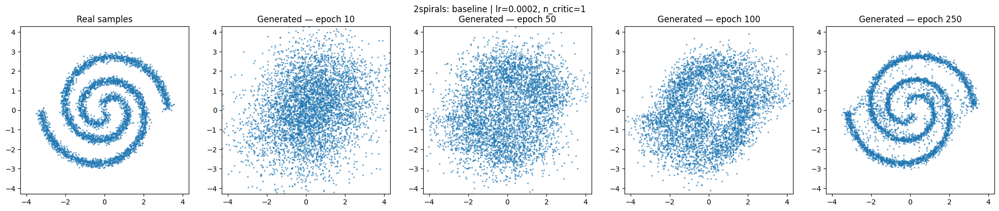

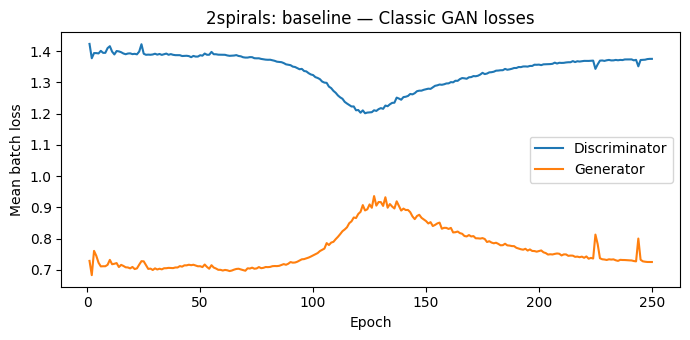

In [ ]:
result_spirals_baseline = train_classic_gan(
    dataset='2spirals', experiment='baseline',
    lr=2e-4, n_critic=1, epochs=250
)

2spirals Experiment 2: Lower Learning Rate

2spirals / lower_lr: epoch 10/250, G=0.711, D=1.392
2spirals / lower_lr: epoch 50/250, G=0.707, D=1.387
2spirals / lower_lr: epoch 100/250, G=0.700, D=1.382
2spirals / lower_lr: epoch 250/250, G=0.777, D=1.310


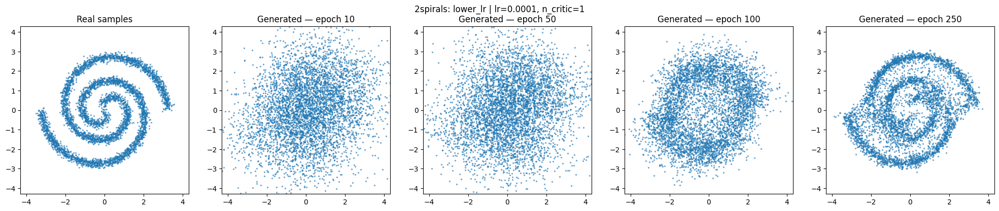

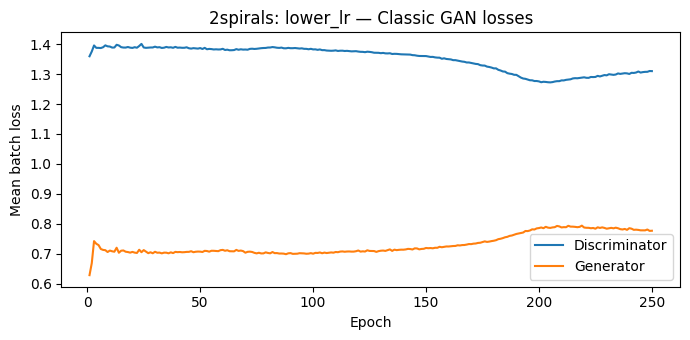

In [ ]:
result_spirals_lower_lr = train_classic_gan(
    dataset='2spirals', experiment='lower_lr',
    lr=1e-4, n_critic=1, epochs=250
)

2spirals Experiment 3: More Discriminator Updates

2spirals / more_d_steps: epoch 10/250, G=0.705, D=1.375
2spirals / more_d_steps: epoch 50/250, G=1.669, D=0.838
2spirals / more_d_steps: epoch 100/250, G=1.761, D=0.777
2spirals / more_d_steps: epoch 250/250, G=0.913, D=1.177


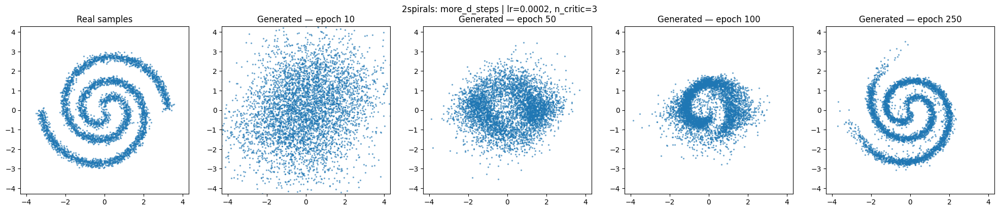

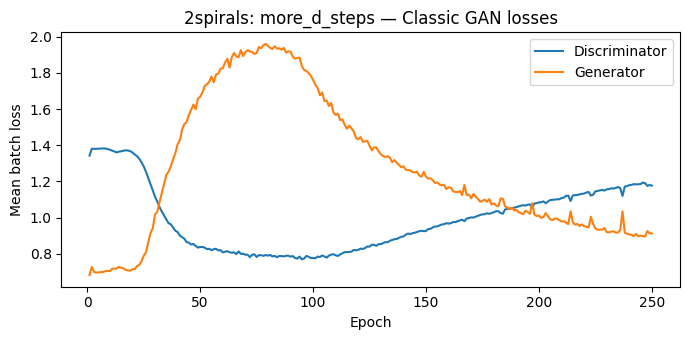

In [ ]:
result_spirals_more_d_steps = train_classic_gan(
    dataset='2spirals', experiment='more_d_steps',
    lr=2e-4, n_critic=3, epochs=250
)

2spirals Experiment 4: Wider Network



2spirals / wider_network: epoch 10/250, G=0.714, D=1.392
2spirals / wider_network: epoch 50/250, G=0.709, D=1.388
2spirals / wider_network: epoch 100/250, G=0.725, D=1.356
2spirals / wider_network: epoch 250/250, G=0.724, D=1.378


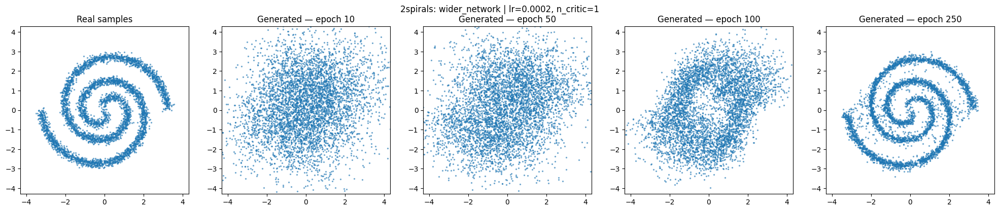

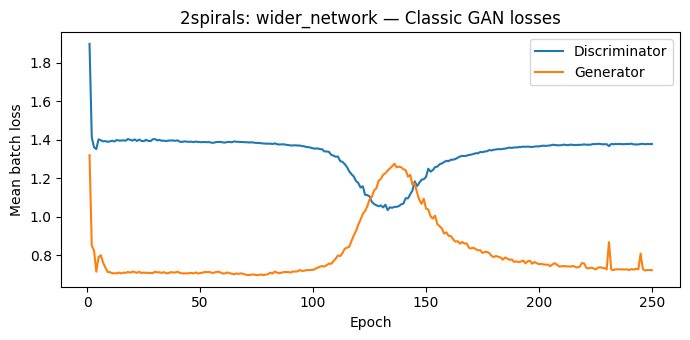

In [ ]:
result_spirals_wider = train_classic_gan(
    dataset="2spirals",
    experiment="wider_network",
    lr=2e-4,
    n_critic=1,
    epochs=250,
    hidden=(512, 512, 512)
)

2spirals Experiment 5A - Adam Optimizer

2spirals / adam_comparison: epoch 10/250, G=0.732, D=1.416
2spirals / adam_comparison: epoch 50/250, G=0.712, D=1.387
2spirals / adam_comparison: epoch 100/250, G=0.747, D=1.323
2spirals / adam_comparison: epoch 250/250, G=0.725, D=1.375


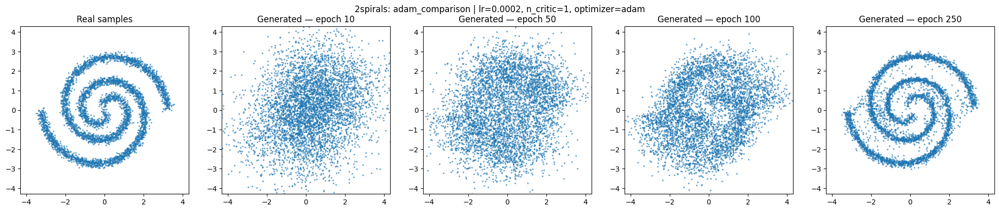

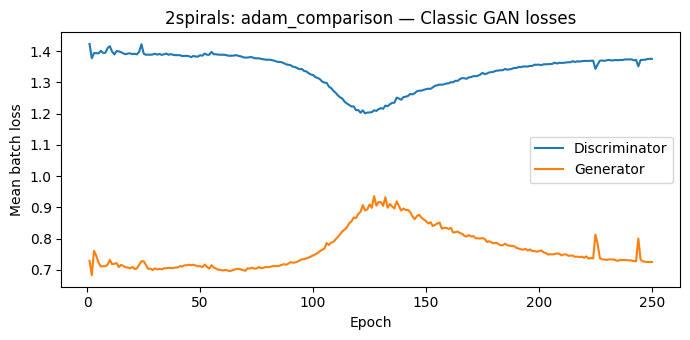

In [ ]:
result_spirals_adam = train_classic_gan(
    dataset="2spirals",
    experiment="adam_comparison",
    optimizer="adam"
)

2spirals Experiment 5B - RMSProp Optimizer

2spirals / rmsprop_comparison: epoch 10/250, G=0.731, D=1.417
2spirals / rmsprop_comparison: epoch 50/250, G=0.701, D=1.383
2spirals / rmsprop_comparison: epoch 100/250, G=0.820, D=1.253
2spirals / rmsprop_comparison: epoch 250/250, G=0.806, D=1.352


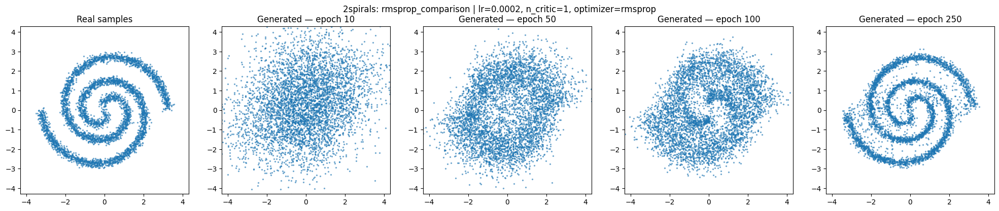

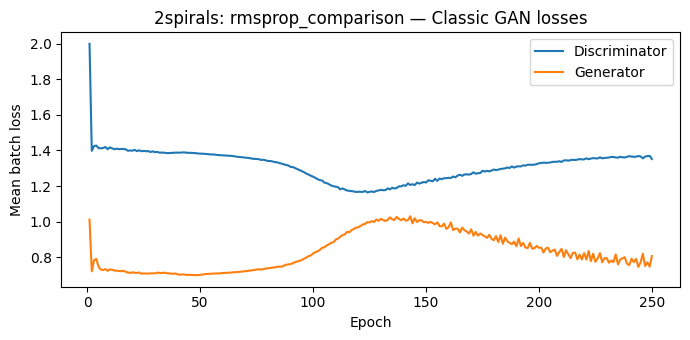

In [ ]:
result_spirals_rmsprop = train_classic_gan(
    dataset="2spirals",
    experiment="rmsprop_comparison",
    optimizer="rmsprop"
)

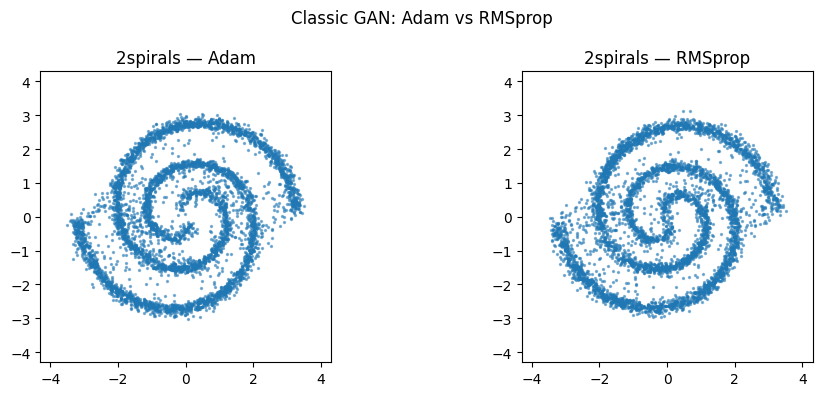

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, result) in zip(axes, [
    ("Adam", result_spirals_adam),
    ("RMSprop", result_spirals_rmsprop)
]):
    samples = result["snapshots"][250]

    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.5)
    ax.set_title(f"2spirals — {name}")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-4.3, 4.3)
    ax.set_aspect("equal", "box")

plt.suptitle("Classic GAN: Adam vs RMSprop")
plt.tight_layout()
plt.show()

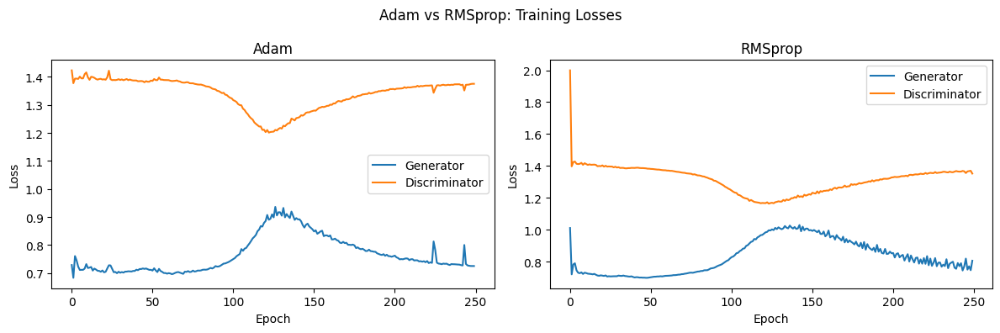

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, result) in zip(axes, [
    ("Adam", result_spirals_adam),
    ("RMSprop", result_spirals_rmsprop)
]):
    ax.plot(result["g_losses"], label="Generator")
    ax.plot(result["d_losses"], label="Discriminator")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.suptitle("Adam vs RMSprop: Training Losses")
plt.tight_layout()
plt.show()

Rings Experiment 1: Baseline

rings / baseline: epoch 10/250, G=0.712, D=1.408
rings / baseline: epoch 50/250, G=0.711, D=1.383
rings / baseline: epoch 100/250, G=0.775, D=1.323
rings / baseline: epoch 250/250, G=0.882, D=1.249


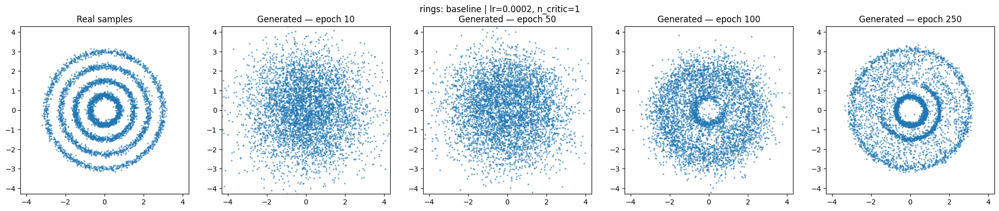

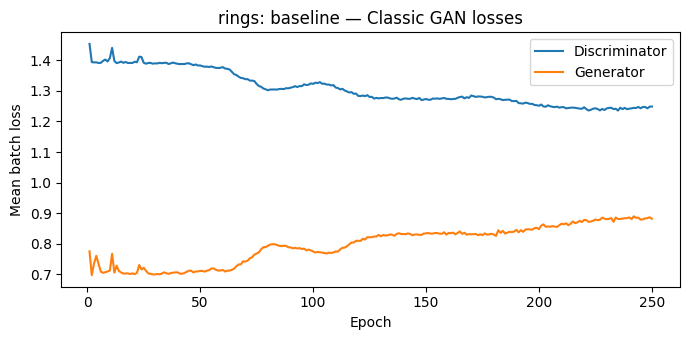

In [ ]:
result_rings_baseline = train_classic_gan(
    dataset='rings', experiment='baseline',
    lr=2e-4, n_critic=1, epochs=250
)

Rings Experiment 2: Lower Learning Rate

rings / lower_lr: epoch 10/250, G=0.706, D=1.392
rings / lower_lr: epoch 50/250, G=0.708, D=1.397
rings / lower_lr: epoch 100/250, G=0.727, D=1.352
rings / lower_lr: epoch 250/250, G=0.848, D=1.255


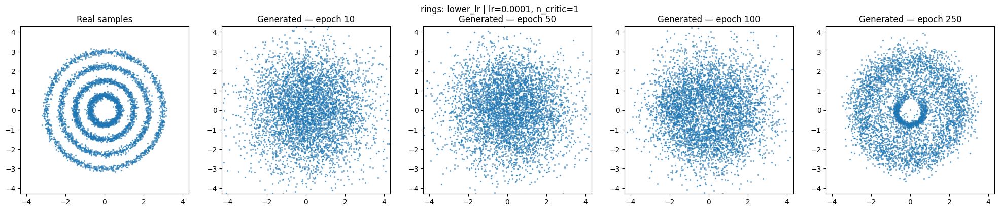

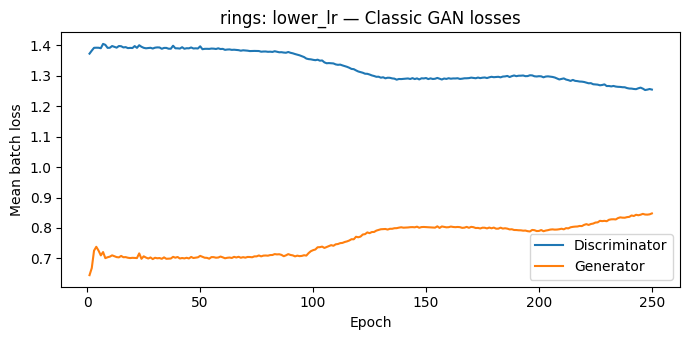

In [ ]:
result_rings_lower_lr = train_classic_gan(
    dataset='rings', experiment='lower_lr',
    lr=1e-4, n_critic=1, epochs=250
)

Rings Experiment 3: More Discriminator Updates

rings / more_d_steps: epoch 10/250, G=0.699, D=1.383
rings / more_d_steps: epoch 50/250, G=1.123, D=1.075
rings / more_d_steps: epoch 100/250, G=2.111, D=0.879
rings / more_d_steps: epoch 250/250, G=1.579, D=0.821


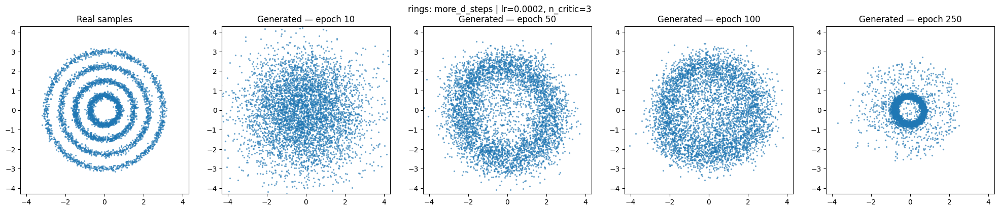

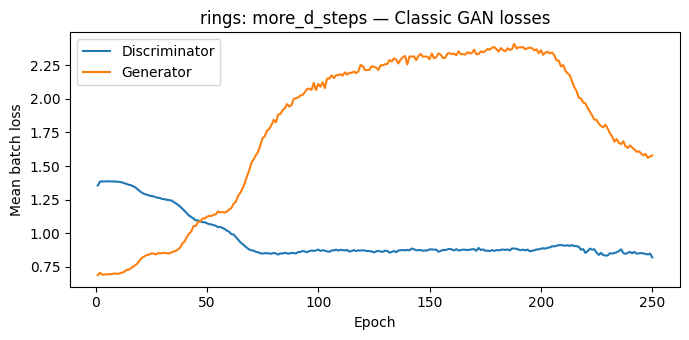

In [ ]:
result_rings_more_d_steps = train_classic_gan(
    dataset='rings', experiment='more_d_steps',
    lr=2e-4, n_critic=3, epochs=250
)

Rings Experiment 4: Wider Network



rings / wider_network: epoch 10/250, G=0.703, D=1.398
rings / wider_network: epoch 50/250, G=0.706, D=1.393
rings / wider_network: epoch 100/250, G=0.812, D=1.285
rings / wider_network: epoch 250/250, G=0.884, D=1.259


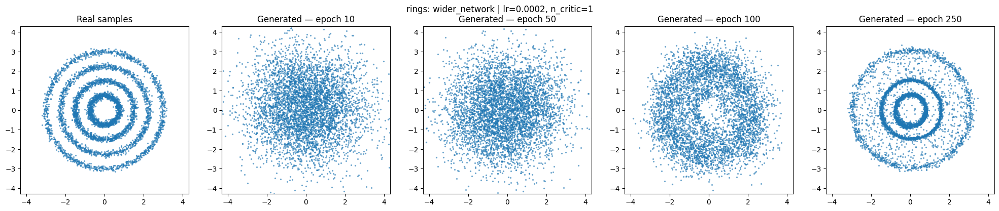

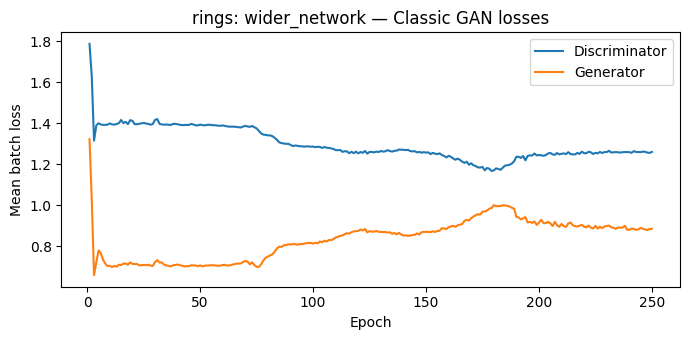

In [ ]:
result_rings_wider = train_classic_gan(
    dataset="rings",
    experiment="wider_network",
    lr=2e-4,
    n_critic=1,
    epochs=250,
    hidden=(512, 512, 512)
)

Rings Experiment 5A - Adam Optimizer

rings / adam_comparison: epoch 10/250, G=0.712, D=1.408
rings / adam_comparison: epoch 50/250, G=0.711, D=1.383
rings / adam_comparison: epoch 100/250, G=0.775, D=1.323
rings / adam_comparison: epoch 250/250, G=0.882, D=1.249


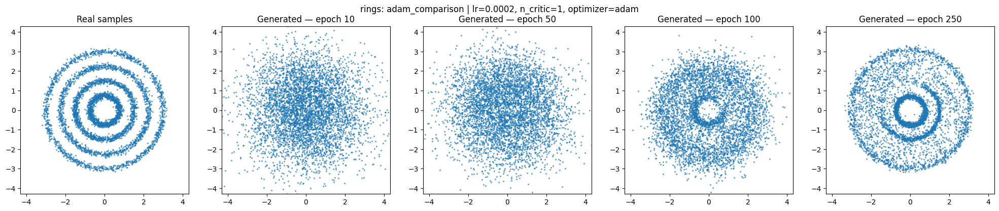

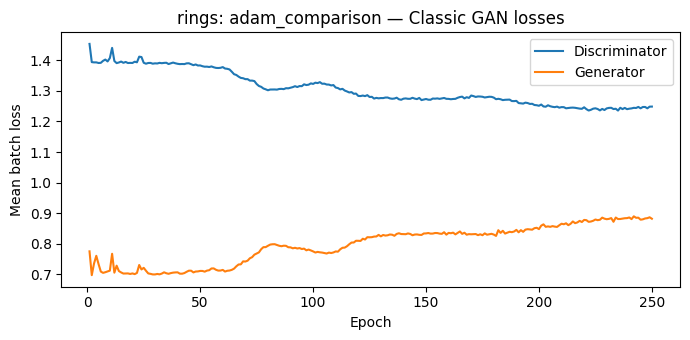

In [ ]:
result_rings_adam = train_classic_gan(
    dataset="rings",
    experiment="adam_comparison",
    optimizer="adam"
)

Rings Experiment 5B - RMSProp Optimizer

rings / rmsprop_comparison: epoch 10/250, G=0.719, D=1.410
rings / rmsprop_comparison: epoch 50/250, G=0.761, D=1.331
rings / rmsprop_comparison: epoch 100/250, G=0.858, D=1.233
rings / rmsprop_comparison: epoch 250/250, G=0.928, D=1.224


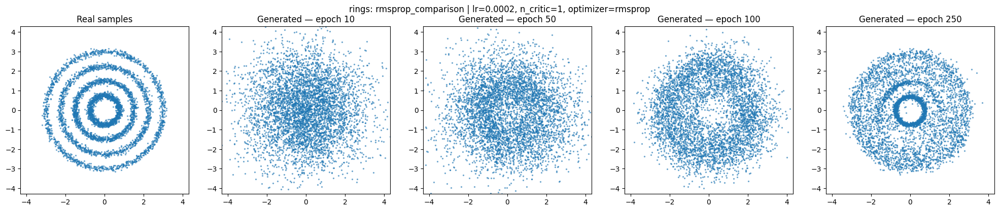

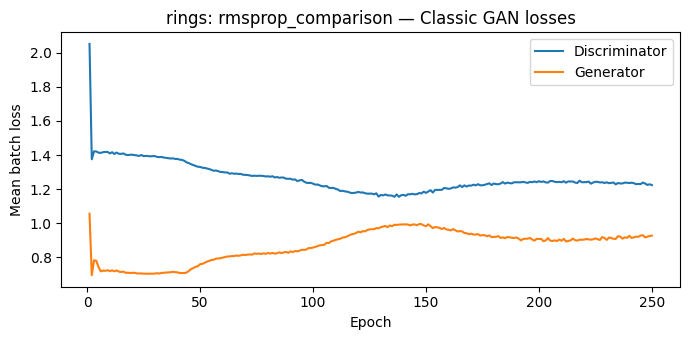

In [ ]:
result_rings_rmsprop = train_classic_gan(
    dataset="rings",
    experiment="rmsprop_comparison",
    optimizer="rmsprop"
)

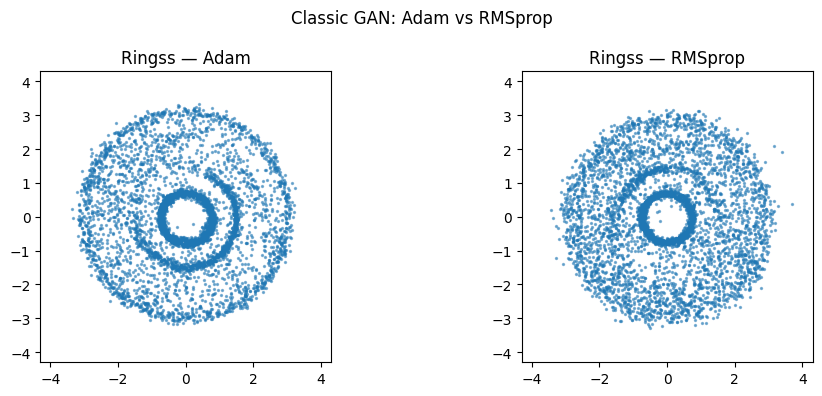

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, result) in zip(axes, [
    ("Adam", result_rings_adam),
    ("RMSprop", result_rings_rmsprop)
]):
    samples = result["snapshots"][250]

    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.5)
    ax.set_title(f"Ringss — {name}")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-4.3, 4.3)
    ax.set_aspect("equal", "box")

plt.suptitle("Classic GAN: Adam vs RMSprop")
plt.tight_layout()
plt.show()

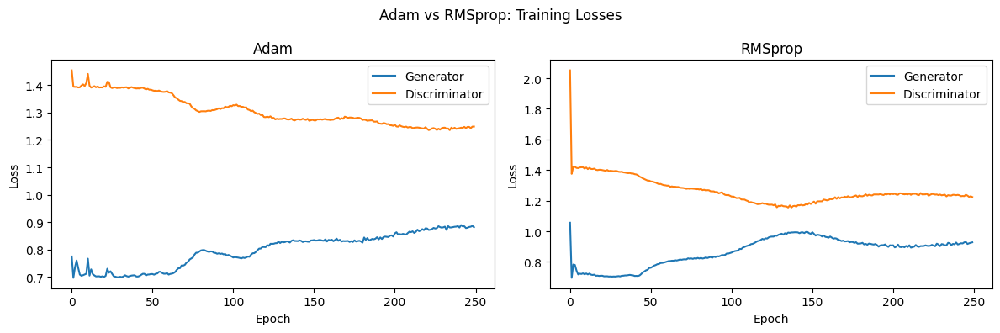

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, result) in zip(axes, [
    ("Adam", result_rings_adam),
    ("RMSprop", result_rings_rmsprop)
]):
    ax.plot(result["g_losses"], label="Generator")
    ax.plot(result["d_losses"], label="Discriminator")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.suptitle("Adam vs RMSprop: Training Losses")
plt.tight_layout()
plt.show()

## Problem 4.1 — Classic GAN: Experimental Results

### Experimental Setup

I trained a classic GAN on the `2spirals` and `rings` datasets for 250 epochs, comparing different learning rates, discriminator updates, network widths, and optimizers (Adam and RMSprop).

### 1. Two Spirals Dataset

The GAN learned recognizable two-spiral structures in several experiments, although some configurations showed incomplete coverage of the target distribution. The baseline configuration (learning rate = 0.0002, one discriminator update) produced recognizable spirals by epoch 250, showing good convergence.

Reducing the learning rate to 0.0001 resulted in less defined spirals, suggesting slower or incomplete convergence. Increasing discriminator updates to three produced recognizable spirals but with uneven sample coverage. The wider network also captured the spiral structure well.

Both Adam and RMSprop generated recognizable spirals by the final epoch, suggesting that both optimizers were effective for this dataset under the tested settings.

**Successful run:** Baseline GAN — generated samples closely followed both spirals.

**Weaker run:** Lower learning rate — generated samples were less clearly organized along the spiral structure.

### 2. Rings Dataset

The rings dataset was more difficult for the GAN. Instead of reproducing all the concentric rings, most experiments generated points concentrated in a broad circular region.

The baseline and lower-learning-rate configurations partially captured the circular distribution but failed to reproduce the distinct rings. Increasing discriminator updates to three produced a much narrower concentration of samples, suggesting reduced diversity and possible mode collapse.

The wider network captured some ring structure but still failed to represent all the rings. Neither Adam nor RMSprop reproduced the complete distribution.

**Relatively successful run:** Wider network — generated some recognizable ring structure.

**Failed run:** Three discriminator updates — samples concentrated in a small circular region and missed most of the rings.

### 3. Conclusion

The classic GAN performed better on `2spirals` than on `rings`. Several configurations successfully learned the spiral structure, while the rings experiments struggled to capture all modes of the distribution.

Changing the learning rate, network width, discriminator updates, and optimizer affected convergence and sample diversity. More discriminator updates did not consistently improve performance and appeared to reduce diversity on the rings dataset. Overall, the experiments illustrate that classic GAN training can be sensitive to hyperparameters and may experience mode collapse or incomplete distribution coverage.

## Vanilla GAN (Optional, you can play with it if you want)

In [ ]:
z_dim = 16
G = MLPGenerator(z_dim=z_dim).to(device)
D = MLPDiscriminator().to(device)
G.apply(weights_init); D.apply(weights_init)

sum_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"G params: {sum_params(G):,} | D params: {sum_params(D):,}")

G params: 136,450 | D params: 132,609


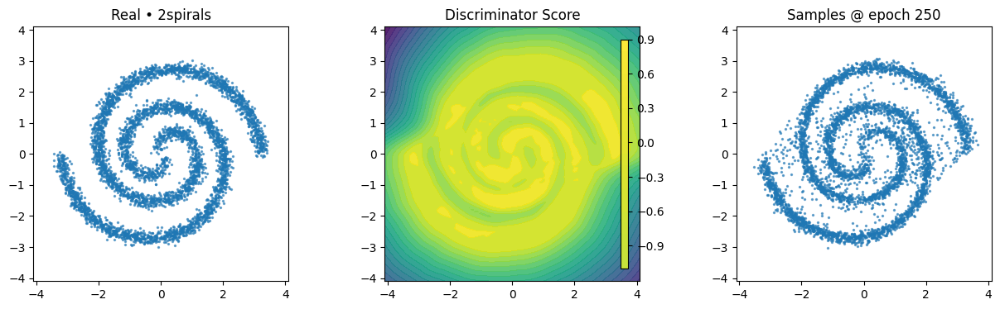

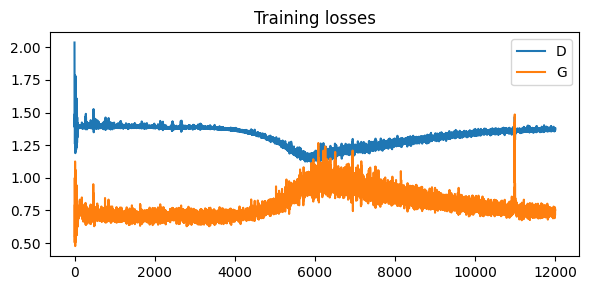

In [ ]:
# === Visualization setup ===
VIZ_GRID_N = 140
xs, ys, grid_t = make_grid(n=VIZ_GRID_N, device=device)
viz_noise = torch.randn(5000, z_dim, device=device)
push_snapshot = init_live_browser()

# === Vanilla GAN training ===
lr = 2e-4
beta1, beta2 = 0.5, 0.999
epochs = 250
n_critic = 1

opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, beta2))
opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, beta2))
bce_logits = nn.BCEWithLogitsLoss()

g_losses, d_losses = [], []

for epoch in range(1, epochs+1):
    G.train(); D.train()
    pbar = tqdm(dl, desc=f"[Epoch {epoch}/{epochs}]", leave=False)
    for real_batch, in pbar:
        real = real_batch.to(device, non_blocking=True)     # (B,2)
        B = real.size(0)

        # ===== 1) Update Discriminator =====
        for _ in range(n_critic):
            z = torch.randn(B, z_dim, device=device)
            with torch.no_grad():
                fake_detached = G(z)                        # (B,2)
            D_real = D(real)                                # logits
            D_fake = D(fake_detached)
            d_loss = bce_logits(D_real, torch.ones_like(D_real)) + \
                     bce_logits(D_fake, torch.zeros_like(D_fake))
            opt_D.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_D.step()

        # ===== 2) Update Generator (non-saturating) =====
        z = torch.randn(B, z_dim, device=device)
        fake = G(z)
        D_fake_for_G = D(fake)
        g_loss = bce_logits(D_fake_for_G, torch.ones_like(D_fake_for_G))
        opt_G.zero_grad(set_to_none=True)
        g_loss.backward()
        opt_G.step()

        g_losses.append(g_loss.item()); d_losses.append(d_loss.item())
        pbar.set_postfix(d=f"{d_loss.item():.3f}", g=f"{g_loss.item():.3f}")

    if epoch % 10 == 0 or epoch == epochs:
        snap = capture_snapshot(G, D, X_real, viz_noise, xs, ys, grid_t, data_type, device, epoch)
        push_snapshot(snap)

plt.figure(figsize=(6,3))
plt.plot(d_losses, label="D"); plt.plot(g_losses, label="G")
plt.legend(); plt.title("Training losses"); plt.tight_layout(); plt.show()

## WGAN-GP

In [ ]:
z_dim = 16
G = MLPGenerator(z_dim=z_dim).to(device)
D = MLPDiscriminator().to(device)
G.apply(weights_init); D.apply(weights_init)

sum_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"G params: {sum_params(G):,} | D params: {sum_params(D):,}")

G params: 136,450 | D params: 132,609


### 🧩 Task: Implement the one-sided **variance** Gradient Penalty

👉 In your function `gradient_penalty`,
replace the standard GP with the “variance” version from *Remark 2*, which penalizes only when  

$$
|\nabla_{\hat x} D(\hat x)|^2 > 1
$$



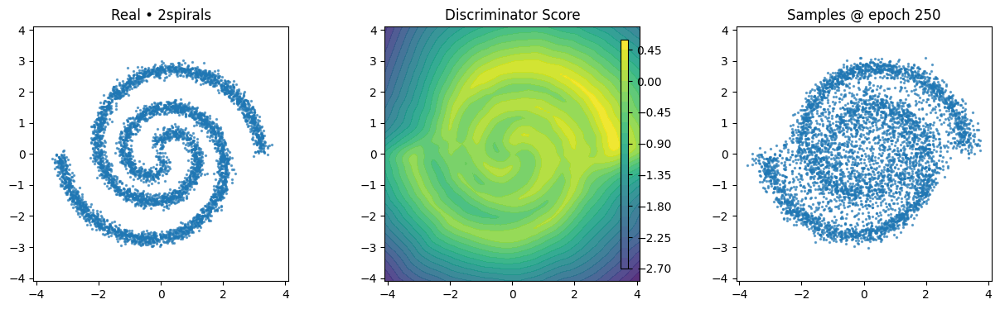

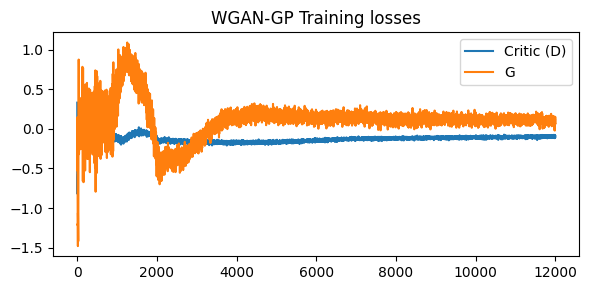

In [ ]:
# --- Visualization setup ---
VIZ_GRID_N = 140
xs, ys, grid_t = make_grid(n=VIZ_GRID_N, device=device)
viz_noise = torch.randn(5000, z_dim, device=device)
push_snapshot = init_live_browser()

# --- WGAN-GP settings ---
lr_G, lr_D = 1e-4, 1e-4
beta1, beta2 = 0.0, 0.9
epochs = 250
n_critic = 2
gp_lambda = 1.0

one_side_gp = True

opt_G = torch.optim.Adam(G.parameters(), lr=lr_G, betas=(beta1, beta2))
opt_D = torch.optim.Adam(D.parameters(), lr=lr_D, betas=(beta1, beta2))

# --- WGAN-GP gradient penalty ---
def gradient_penalty(D, real, fake, one_side=True, return_norm=False):
    B = real.size(0)
    mixing = torch.rand(B, *([1] * (real.dim() - 1)), device=real.device)
    x_hat = mixing * real + (1.0 - mixing) * fake
    x_hat.requires_grad_(True)

    d_hat = D(x_hat)
    grad_outputs = torch.ones_like(d_hat, device=x_hat.device)

    grads = torch.autograd.grad(
        outputs=d_hat,
        inputs=x_hat,
        grad_outputs=grad_outputs,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]

    gn = grads.flatten(1).norm(2, dim=1)
    if one_side:
        """
        Implement the one-sided variance GP
        """
        gp = torch.relu(gn.pow(2) - 1.0).pow(2).mean()
    else:
        gp = (gn - 1.0).pow(2).mean()

    return (gp, gn.mean()) if return_norm else gp


g_losses, d_losses = [], []

for epoch in range(1, epochs+1):
    G.train(); D.train()
    pbar = tqdm(dl, desc=f"[Epoch {epoch}/{epochs}]", leave=False)

    for real_batch, in pbar:
        real = real_batch.to(device, non_blocking=True)     # (B,2)
        B = real.size(0)

        # ===== 1) Update Critic n_critic times =====
        for _ in range(n_critic):
            z = torch.randn(B, z_dim, device=device)
            with torch.no_grad():
                fake_detached = G(z)

            D_real = D(real).view(-1)
            D_fake = D(fake_detached).view(-1)

            W = D_real.mean() - D_fake.mean()
            gp, gn_mean = gradient_penalty(
                D, real, fake_detached,
                one_side=one_side_gp,
                return_norm=True
            )

            drift = 0.001 * (D_real.pow(2).mean())
            d_loss = (D_fake.mean() - D_real.mean()) + gp_lambda * gp + drift

            opt_D.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_D.step()

        # ===== 2) Update Generator =====
        z = torch.randn(B, z_dim, device=device)
        fake = G(z)
        g_loss = - D(fake).view(-1).mean()

        opt_G.zero_grad(set_to_none=True)
        g_loss.backward()
        opt_G.step()

        g_losses.append(g_loss.item()); d_losses.append(d_loss.item())
        pbar.set_postfix(
            d=f"{d_loss.item():.3f}",
            g=f"{g_loss.item():.3f}",
            W=f"{W.item():.3f}",
            gp=f"{gp.item():.3f}",
            gn=f"{gn_mean.item():.2f}",
        )
        pbar.set_postfix(d=f"{d_loss.item():.3f}", g=f"{g_loss.item():.3f}")

    # Visualization every few epochs
    if epoch % 10 == 0 or epoch == epochs:
        snap = capture_snapshot(G, D, X_real, viz_noise, xs, ys, grid_t, data_type, device, epoch)
        push_snapshot(snap)

plt.figure(figsize=(6,3))
plt.plot(d_losses, label="Critic (D)"); plt.plot(g_losses, label="G")
plt.legend(); plt.title("WGAN-GP Training losses"); plt.tight_layout(); plt.show()


### Part 2: One-Sided Variance Gradient Penalty

I implemented the one-sided variance gradient penalty for WGAN using:

```python
gp = torch.relu(gn.pow(2) - 1.0).pow(2).mean()
```

**Sampling:** I sample interpolated points between real and generated samples using:

$$
\hat{x} = \epsilon x_{\text{real}} + (1-\epsilon)x_{\text{fake}}
$$

where $\epsilon \sim U(0,1)$ is randomly sampled from a uniform distribution between 0 and 1.

**Gradient computation:** I use `torch.autograd.grad()` to compute the critic's gradient with respect to the interpolated samples. I then calculate the L2 norm of the gradient for each sample.

**Gradient penalty:** The penalty applies only when the squared gradient norm exceeds 1. I use `torch.relu()` to set negative values to zero, square the remaining values, and average across the batch.

**Critic loss:** I add the penalty to the critic loss using `gp_lambda * gp`, along with the existing drift regularization term. This discourages excessively large gradients and helps enforce the Lipschitz constraint during training.

In [ ]:

from pathlib import Path

WGAN_DIR = Path("wgan_results")
WGAN_DIR.mkdir(exist_ok=True)

def train_wgan_experiment(dataset, experiment, gp_lambda=1.0,
                          n_critic=2, epochs=250, seed=42):

    seed_everything(seed)

    # Prepare dataset
    real_cpu = generate_data(
        dataset, batch_size=50000, device="cpu"
    )
    loader = DataLoader(
        TensorDataset(real_cpu),
        batch_size=1024,
        shuffle=True,
        drop_last=True
    )

    # Initialize fresh models
    z_dim = 16
    G = MLPGenerator(z_dim=z_dim).to(device)
    D = MLPDiscriminator().to(device)
    G.apply(weights_init)
    D.apply(weights_init)

    opt_G = torch.optim.Adam(
        G.parameters(), lr=1e-4, betas=(0.0, 0.9)
    )
    opt_D = torch.optim.Adam(
        D.parameters(), lr=1e-4, betas=(0.0, 0.9)
    )

    g_losses, d_losses = [], []
    snapshots = {}
    fixed_z = torch.randn(5000, z_dim, device=device)

    for epoch in range(1, epochs + 1):
        G.train()
        D.train()
        epoch_g, epoch_d, count = 0.0, 0.0, 0

        for (real_batch,) in loader:
            real = real_batch.to(device)
            B = real.size(0)

            # Train critic
            for _ in range(n_critic):
                z = torch.randn(B, z_dim, device=device)

                with torch.no_grad():
                    fake = G(z)

                D_real = D(real).view(-1)
                D_fake = D(fake).view(-1)

                if gp_lambda > 0:
                    gp = gradient_penalty(
                        D, real, fake, one_side=True
                    )
                else:
                    gp = torch.zeros((), device=device)

                drift = 0.001 * D_real.pow(2).mean()

                d_loss = (
                    D_fake.mean() - D_real.mean()
                    + gp_lambda * gp
                    + drift
                )

                opt_D.zero_grad(set_to_none=True)
                d_loss.backward()
                opt_D.step()

            # Train generator
            z = torch.randn(B, z_dim, device=device)
            fake = G(z)
            g_loss = -D(fake).view(-1).mean()

            opt_G.zero_grad(set_to_none=True)
            g_loss.backward()
            opt_G.step()

            epoch_g += g_loss.item()
            epoch_d += d_loss.item()
            count += 1

        g_losses.append(epoch_g / count)
        d_losses.append(epoch_d / count)

        if epoch in (10, 50, 100, epochs):
            G.eval()
            with torch.no_grad():
                snapshots[epoch] = G(fixed_z).cpu().numpy()

            print(
                f"{dataset} - {experiment}: "
                f"Epoch {epoch}/{epochs}"
            )

    # Plot sample distributions
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    ref = real_cpu[:5000].numpy()
    axes[0].scatter(ref[:, 0], ref[:, 1], s=2)
    axes[0].set_title("Real data")

    for ax, epoch in zip(axes[1:], sorted(snapshots)):
        samples = snapshots[epoch]
        ax.scatter(samples[:, 0], samples[:, 1], s=2)
        ax.set_title(f"Epoch {epoch}")

    for ax in axes:
        ax.set_xlim(-4.3, 4.3)
        ax.set_ylim(-4.3, 4.3)
        ax.set_aspect("equal")

    fig.suptitle(
        f"{dataset}: {experiment}, "
        f"GP={gp_lambda}, n_critic={n_critic}"
    )
    plt.tight_layout()
    plt.savefig(
        WGAN_DIR / f"{dataset}_{experiment}_samples.png",
        dpi=150
    )
    plt.show()

    # Plot losses
    plt.figure(figsize=(7, 4))
    plt.plot(d_losses, label="Critic")
    plt.plot(g_losses, label="Generator")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{dataset}: {experiment} Losses")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        WGAN_DIR / f"{dataset}_{experiment}_losses.png",
        dpi=150
    )
    plt.show()

    return {
        "snapshots": snapshots,
        "g_losses": g_losses,
        "d_losses": d_losses,
        "gp_lambda": gp_lambda,
        "n_critic": n_critic
    }


In [ ]:
configs = [
    ("no_gp_2", 0.0, 2),
    ("gp_1_2", 1.0, 2),
    ("gp_10_2", 10.0, 2),
    ("gp_1_5", 1.0, 5),
    ("no_gp_5", 0.0, 5),
    ("gp_10_5", 10.0, 5),
]

2spirals - no_gp_2: Epoch 10/250
2spirals - no_gp_2: Epoch 50/250
2spirals - no_gp_2: Epoch 100/250
2spirals - no_gp_2: Epoch 250/250


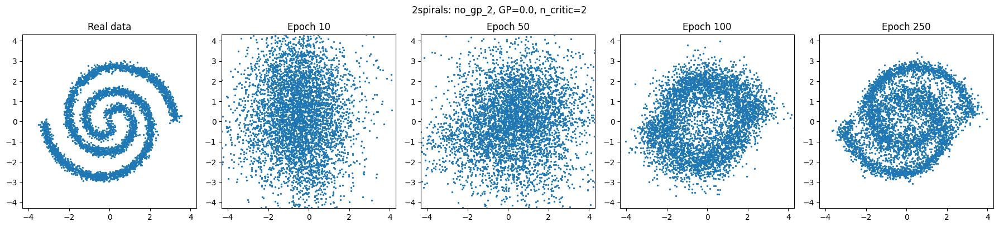

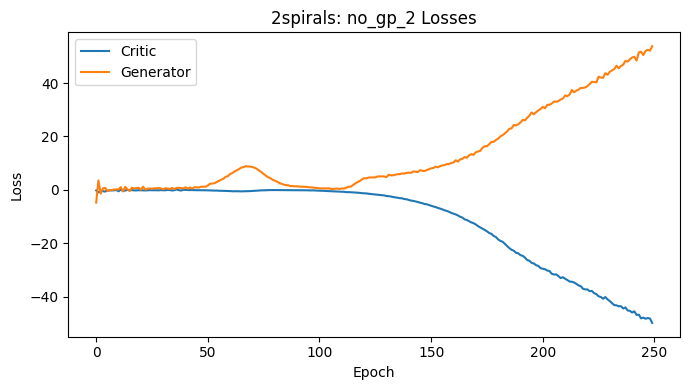

2spirals - gp_1_2: Epoch 10/250
2spirals - gp_1_2: Epoch 50/250
2spirals - gp_1_2: Epoch 100/250
2spirals - gp_1_2: Epoch 250/250


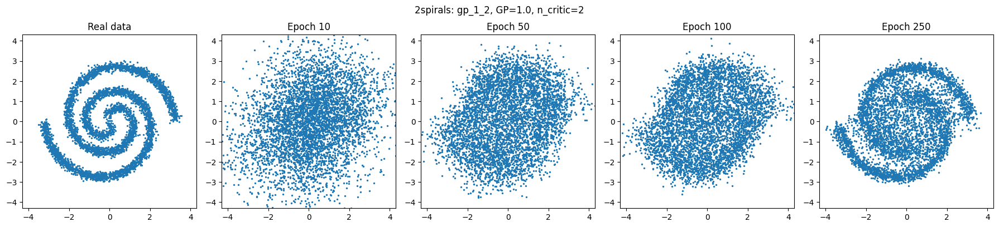

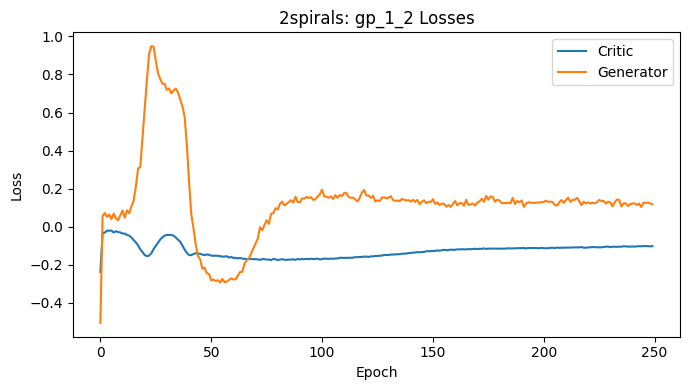

2spirals - gp_10_2: Epoch 10/250
2spirals - gp_10_2: Epoch 50/250
2spirals - gp_10_2: Epoch 100/250
2spirals - gp_10_2: Epoch 250/250


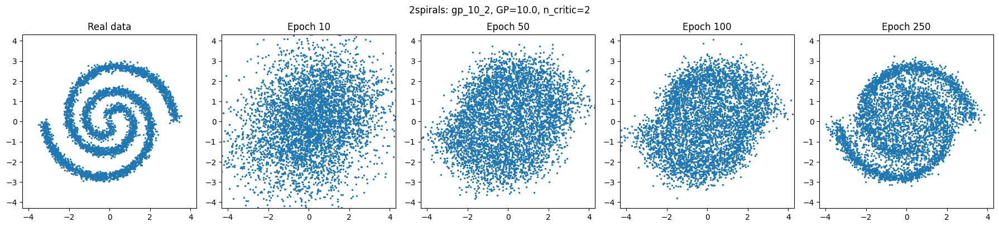

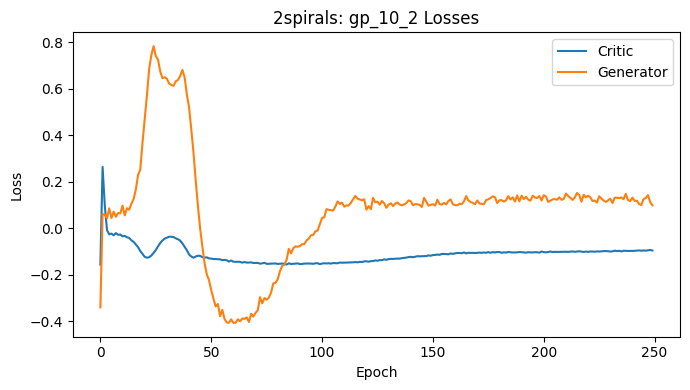

2spirals - gp_1_5: Epoch 10/250
2spirals - gp_1_5: Epoch 50/250
2spirals - gp_1_5: Epoch 100/250
2spirals - gp_1_5: Epoch 250/250


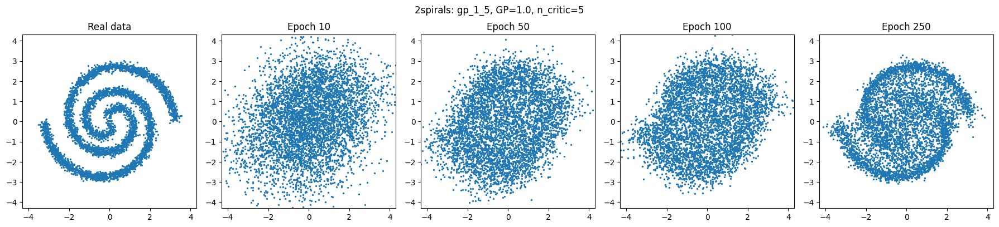

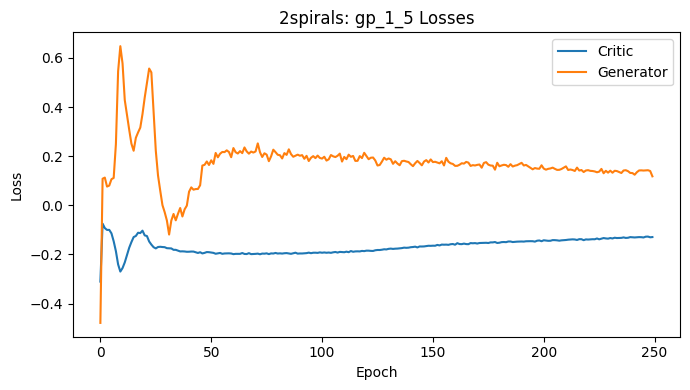

2spirals - no_gp_5: Epoch 10/250
2spirals - no_gp_5: Epoch 50/250
2spirals - no_gp_5: Epoch 100/250
2spirals - no_gp_5: Epoch 250/250


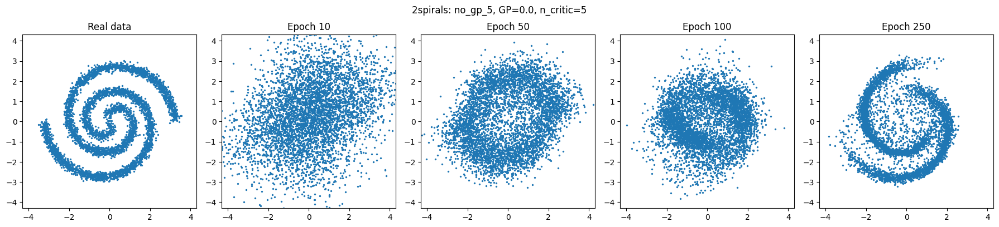

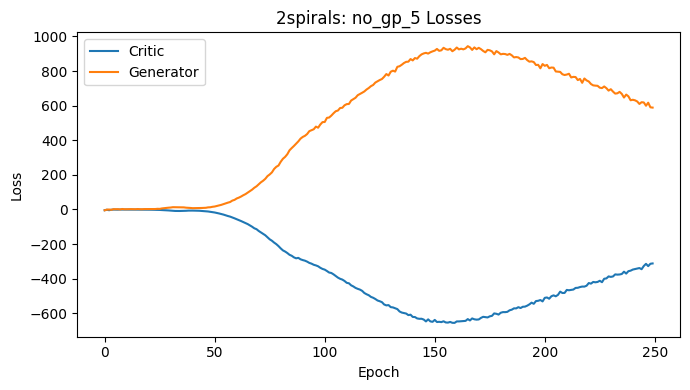

2spirals - gp_10_5: Epoch 10/250
2spirals - gp_10_5: Epoch 50/250
2spirals - gp_10_5: Epoch 100/250
2spirals - gp_10_5: Epoch 250/250


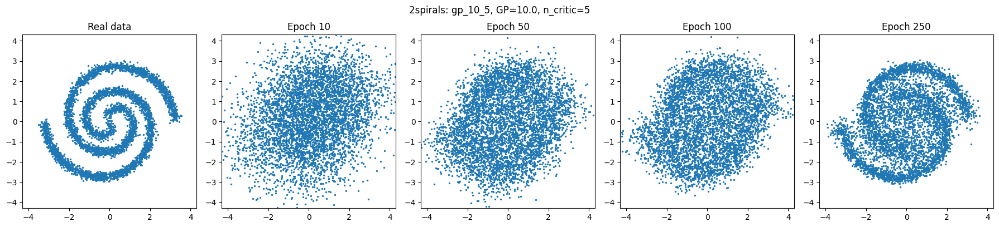

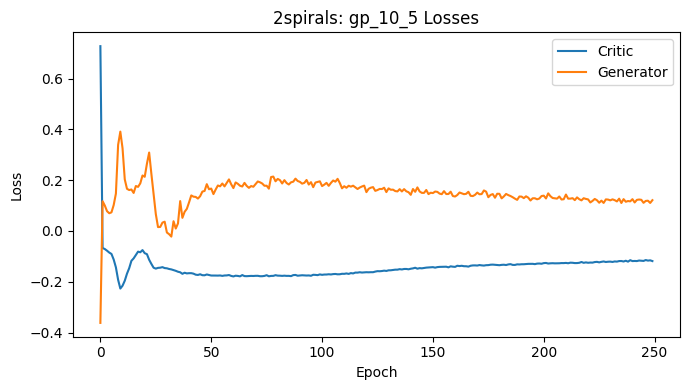

rings - no_gp_2: Epoch 10/250
rings - no_gp_2: Epoch 50/250
rings - no_gp_2: Epoch 100/250
rings - no_gp_2: Epoch 250/250


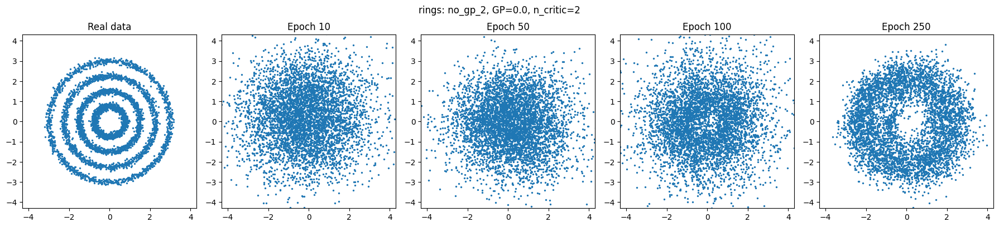

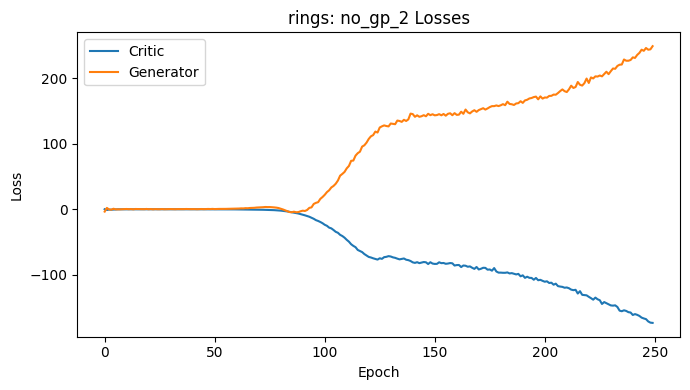

rings - gp_1_2: Epoch 10/250
rings - gp_1_2: Epoch 50/250
rings - gp_1_2: Epoch 100/250
rings - gp_1_2: Epoch 250/250


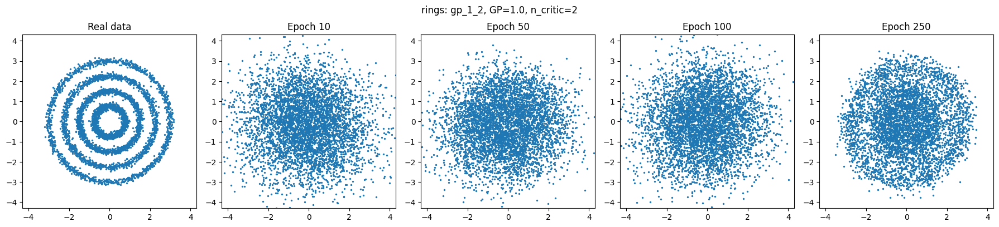

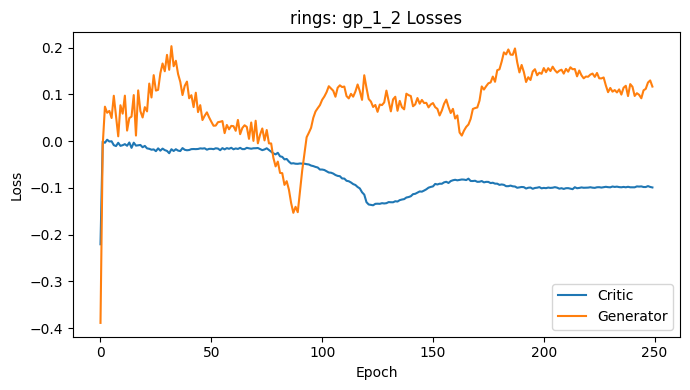

rings - gp_10_2: Epoch 10/250
rings - gp_10_2: Epoch 50/250
rings - gp_10_2: Epoch 100/250
rings - gp_10_2: Epoch 250/250


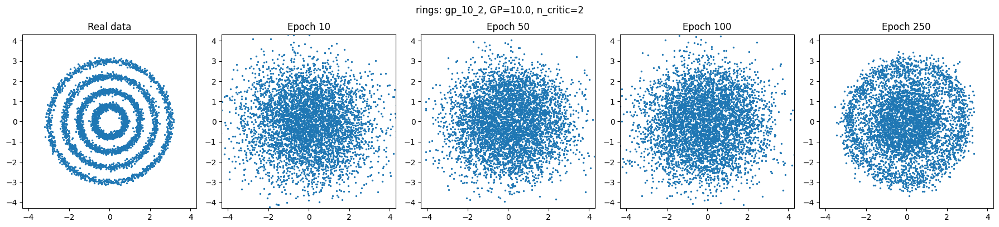

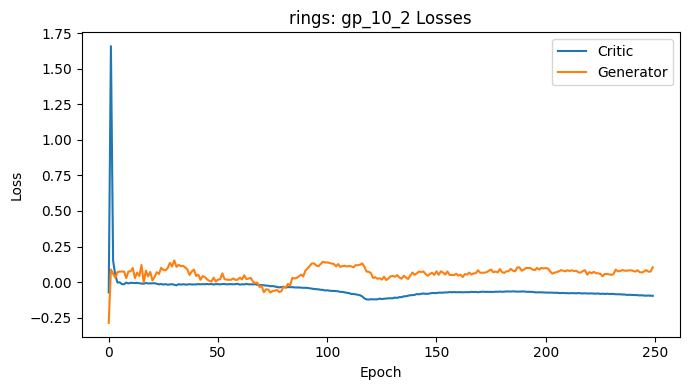

rings - gp_1_5: Epoch 10/250
rings - gp_1_5: Epoch 50/250
rings - gp_1_5: Epoch 100/250
rings - gp_1_5: Epoch 250/250


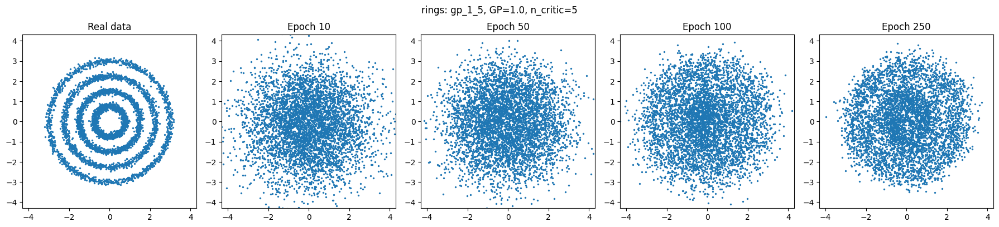

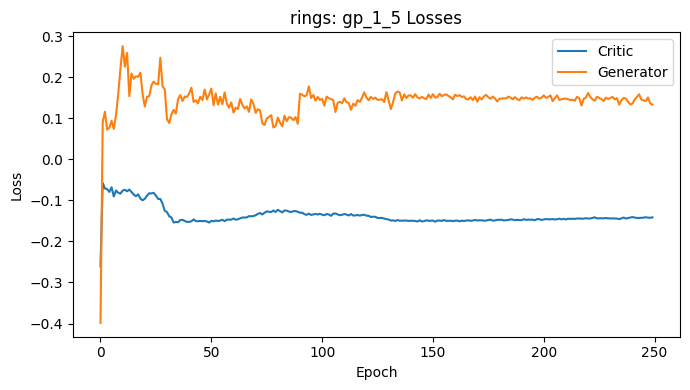

rings - no_gp_5: Epoch 10/250
rings - no_gp_5: Epoch 50/250
rings - no_gp_5: Epoch 100/250
rings - no_gp_5: Epoch 250/250


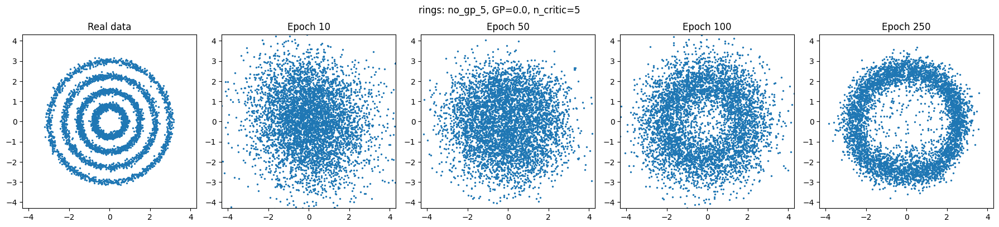

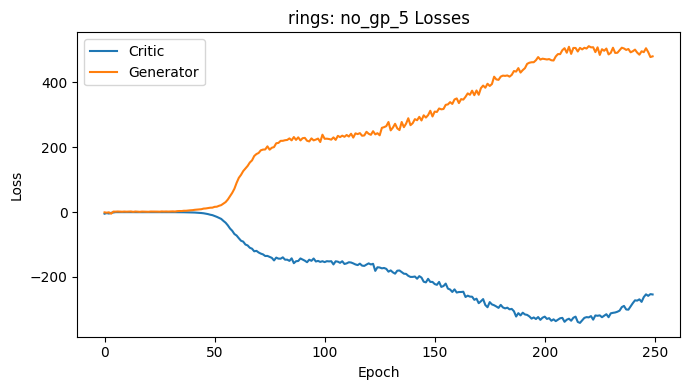

rings - gp_10_5: Epoch 10/250
rings - gp_10_5: Epoch 50/250
rings - gp_10_5: Epoch 100/250
rings - gp_10_5: Epoch 250/250


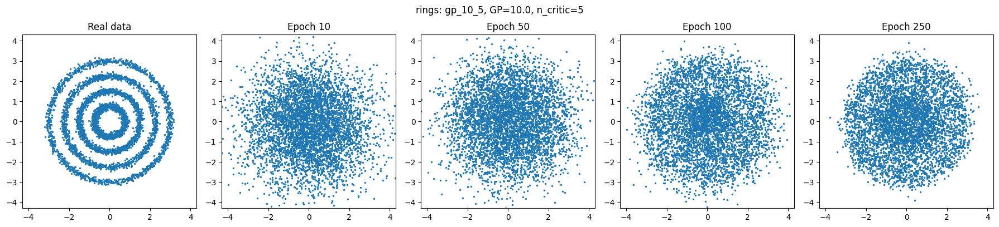

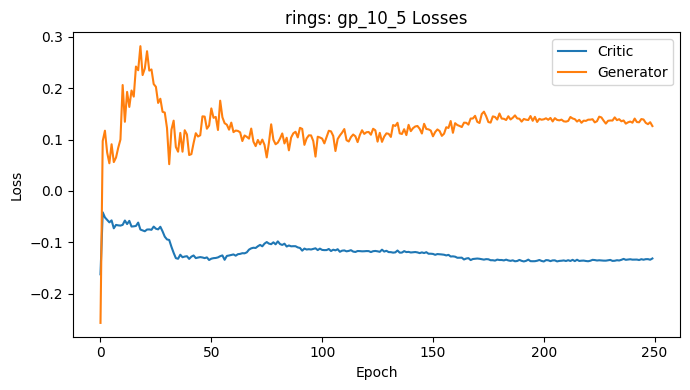

In [ ]:
wgan_results = {}

for dataset in ["2spirals", "rings"]:
    for name, gp_lambda, n_critic in configs:

        key = f"{dataset}_{name}"

        wgan_results[key] = train_wgan_experiment(
            dataset=dataset,
            experiment=name,
            gp_lambda=gp_lambda,
            n_critic=n_critic,
            epochs=250
        )

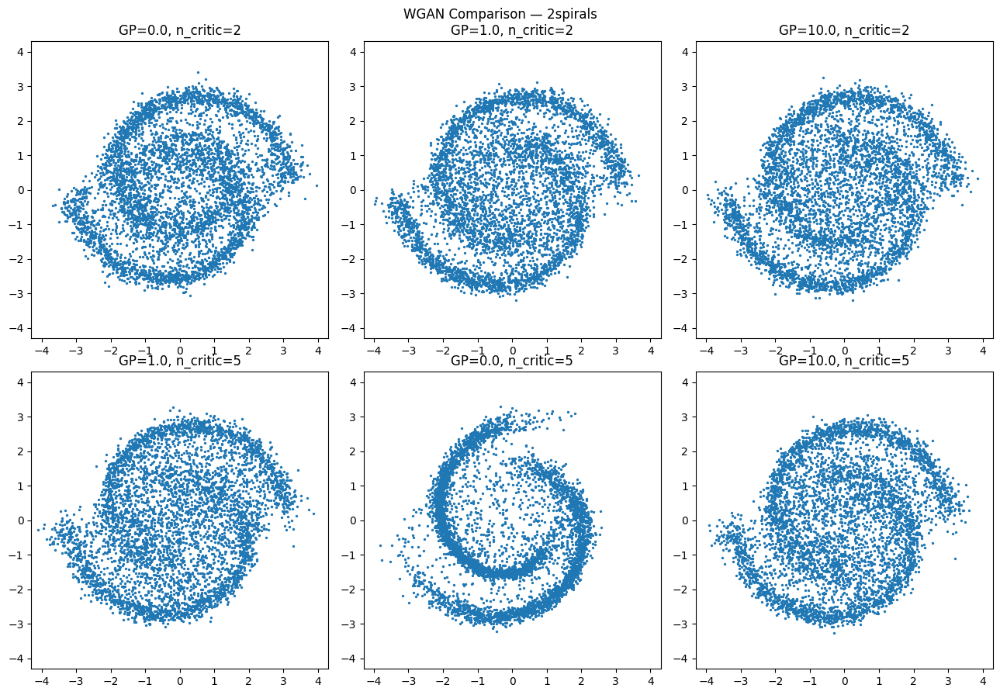

In [ ]:
dataset = "2spirals"

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ax, (name, gp_lambda, n_critic) in zip(
    axes.flat, configs
):
    result = wgan_results[f"{dataset}_{name}"]
    samples = result["snapshots"][250]

    ax.scatter(samples[:, 0], samples[:, 1], s=2)
    ax.set_title(f"GP={gp_lambda}, n_critic={n_critic}")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-4.3, 4.3)
    ax.set_aspect("equal")

plt.suptitle(f"WGAN Comparison — {dataset}")
plt.tight_layout()
plt.show()

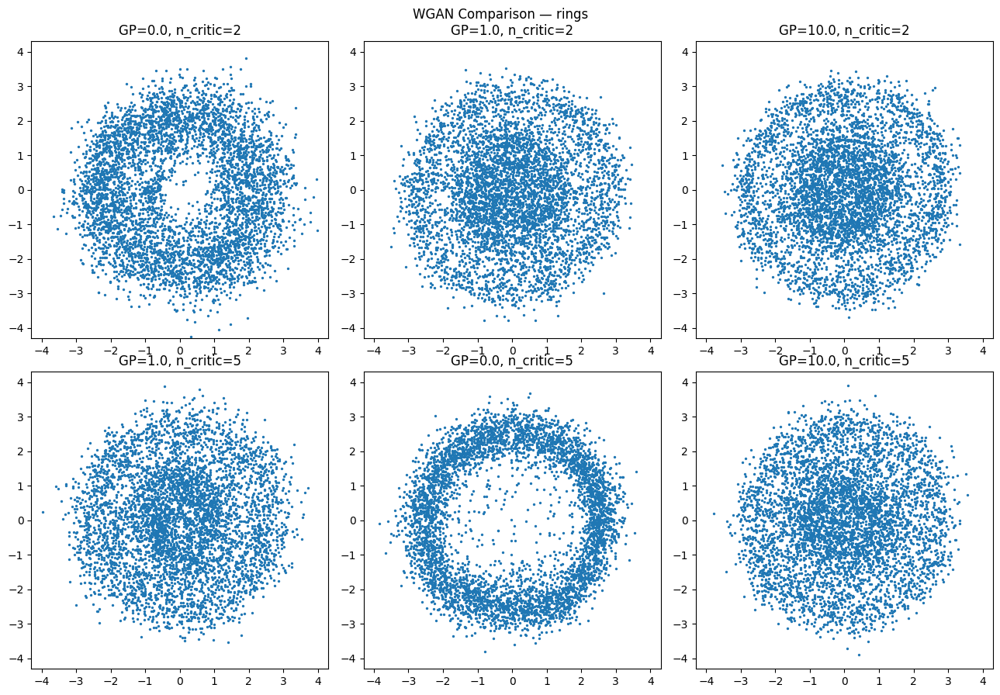

In [ ]:
dataset = "rings"
fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ax, (name, gp_lambda, n_critic) in zip(
    axes.flat, configs
):
    result = wgan_results[f"{dataset}_{name}"]
    samples = result["snapshots"][250]

    ax.scatter(samples[:, 0], samples[:, 1], s=2)
    ax.set_title(f"GP={gp_lambda}, n_critic={n_critic}")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-4.3, 4.3)
    ax.set_aspect("equal")

plt.suptitle(f"WGAN Comparison — {dataset}")
plt.tight_layout()
plt.show()

### Part 3: WGAN With and Without Gradient Penalty

I trained WGAN on the `2spirals` and `rings` datasets using gradient penalty values of 0, 1, and 10, and critic update frequencies of 2 and 5. Each configuration was trained for 250 epochs.

**2spirals:** The best visual result was obtained without gradient penalty (`lambda_GP = 0`, `n_critic = 5`). This configuration produced recognizable curved structures, although it did not completely reproduce both spirals. Adding gradient penalty did not consistently improve the generated distribution, and several configurations produced diffuse samples with incomplete spiral structure.

**Rings:** The best visual result was also obtained without gradient penalty (`lambda_GP = 0`, `n_critic = 5`). The generated samples formed a clear ring-shaped distribution, but failed to capture all concentric rings. Configurations with gradient penalty produced more scattered samples, with some concentrating toward the center.

**Sample quality and diversity:** Increasing critic updates to five improved the visible structure in the best runs, but neither dataset was perfectly reproduced. The results suggest incomplete distribution coverage, with some configurations showing possible mode collapse.

**Stability and loss curves:** Without gradient penalty (`lambda_GP = 0`), the generator loss increased substantially while the critic loss became more negative, especially with `n_critic = 5`. With gradient penalty (`lambda_GP = 1` or `10`), the losses generally showed large initial fluctuations before stabilizing at more bounded values. This behavior was observed across both datasets. The gradient penalty appeared to control the magnitude of the critic and generator losses, although it did not consistently improve the generated sample distributions. Since WGAN losses do not directly measure sample quality, these results suggest more controlled optimization rather than proving convergence.

**Conclusion:** In these experiments, adding the one-sided variance gradient penalty did not consistently improve sample quality. The strongest visual results came from configurations without gradient penalty and with five critic updates. However, visual quality alone is insufficient to determine whether gradient penalty improved training stability.